# 🍷 Wine Classification with K-Nearest Neighbors (KNN)
**Distance-based classification: scaling, choosing K, distance metrics, decision boundaries and the curse of dimensionality**

**Objective:** Implement and understand K-Nearest Neighbors by classifying wines into 3 cultivars from their chemical analysis.
**Tools:** Scikit-learn, Pandas, Matplotlib (+ NumPy)
**Dataset:** the Wine dataset, built into scikit-learn (178 wines × 13 features), so **no download is needed**

**Pipeline**
1. Load & explore the data
2. Why scaling matters: KNN with and without it
3. Choose **K** with cross-validation (bias-variance trade-off)
4. Compare distance metrics and weighting, then tune with a grid search
5. Evaluate on the held-out test set
6. Visualise decision boundaries for different K
7. The curse of dimensionality: KNN vs logistic regression
8. Predict a new wine and inspect its neighbors

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
os.makedirs("images", exist_ok=True)   # plots are saved here
os.makedirs("data", exist_ok=True)
RANDOM_STATE = 42
CLASS_COLORS = ["#e74c3c", "#3498db", "#2ecc71"]
print("✅ Libraries imported")

✅ Libraries imported


## 📥 Step 1: Load & Explore the Data

In [2]:
wine = load_wine(as_frame=True)
df = wine.frame
class_names = list(wine.target_names)
df.to_csv("data/wine.csv", index=False)     # saved so the project can be run offline

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum(), "| Duplicate rows:", df.duplicated().sum())
print("Classes:", class_names)
df.head()

Shape: (178, 14)
Missing values: 0 | Duplicate rows: 0
Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
X = df.drop(columns="target")
y = df["target"]

counts = y.value_counts().sort_index()
print(pd.DataFrame({"class": class_names, "count": counts.values, "%": (counts.values / len(y) * 100).round(1)}))

ranges = X.describe().T[["min", "max", "mean", "std"]].round(2).sort_values("max")
display(ranges)

     class  count     %
0  class_0     59  33.1
1  class_1     71  39.9
2  class_2     48  27.0


,min,max,mean,std
nonflavanoid_phenols,0.13,0.66,0.36,0.12
hue,0.48,1.71,0.96,0.23
ash,1.36,3.23,2.37,0.27
proanthocyanins,0.41,3.58,1.59,0.57
total_phenols,0.98,3.88,2.30,0.63
od280/od315_of_diluted_wines,1.27,4.00,2.61,0.71
flavanoids,0.34,5.08,2.03,1.00
malic_acid,0.74,5.80,2.34,1.12
color_intensity,1.28,13.00,5.06,2.32
alcohol,11.03,14.83,13.00,0.81


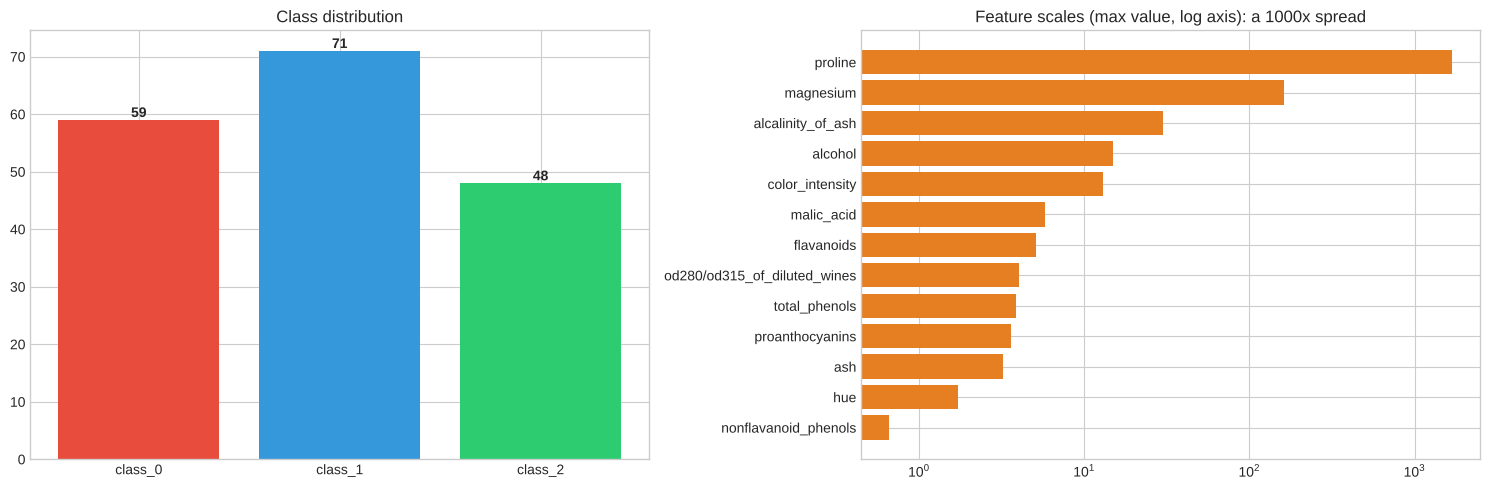

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(class_names, counts.values, color=CLASS_COLORS)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, str(v), ha="center", va="bottom", fontweight="bold")
axes[0].set_title("Class distribution")

axes[1].barh(ranges.index, ranges["max"], color="#e67e22")
axes[1].set_xscale("log")
axes[1].set_title("Feature scales (max value, log axis): a 1000x spread")
plt.tight_layout()
plt.savefig("images/01_classes_and_scales.png", dpi=150, bbox_inches="tight")
plt.show()

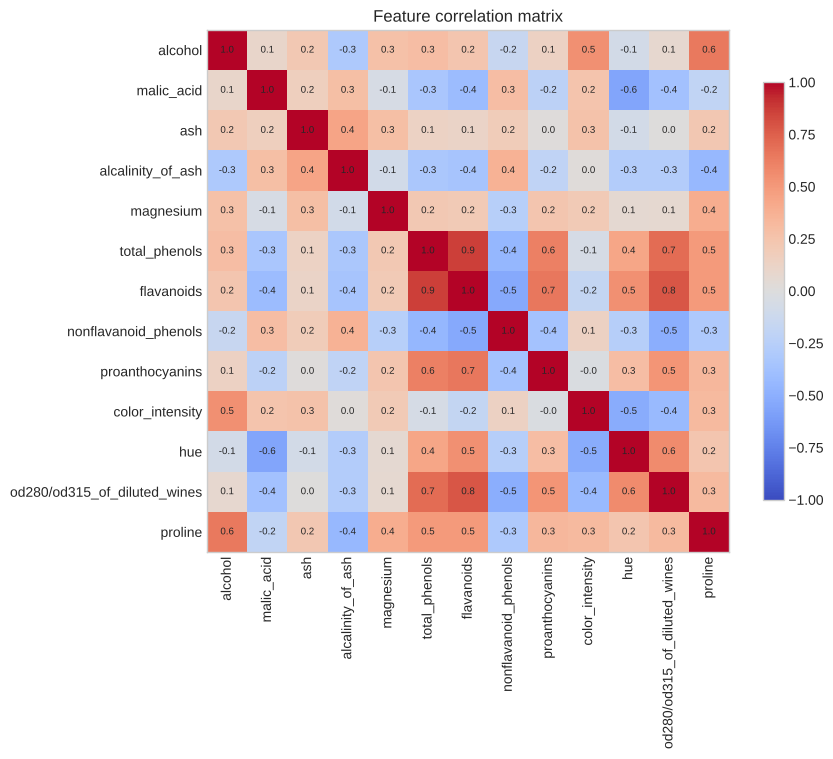

In [5]:
corr = X.corr()
plt.figure(figsize=(9, 7.5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(shrink=0.8)
plt.xticks(range(len(corr)), corr.columns, rotation=90); plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.title("Feature correlation matrix")
plt.grid(False)
plt.tight_layout()
plt.savefig("images/02_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations
- **178 wines, 13 numeric features, 3 classes** (59 / 71 / 48), no missing values: a mildly imbalanced, clean dataset
- **Feature scales differ enormously:** `proline` ranges from 278 to 1,680 (std ≈ 315) while `nonflavanoid_phenols` ranges from 0.13 to 0.66 (std ≈ 0.12)
- KNN is **distance-based**, so features with big numbers will dominate the distance. Scaling is essential
- `flavanoids`, `total_phenols` and `od280/od315` are strongly correlated (up to 0.86)

## ✂️ Step 2: Split the Data & See Why Scaling Matters
Stratified 80/20 split: **142 training** wines, **36 test** wines. The test set stays untouched until the very end.

Train: (142, 13) | Test: (36, 13)


,Test accuracy,5-fold CV accuracy
KNN without scaling,0.806,0.705
KNN with StandardScaler,0.972,0.951


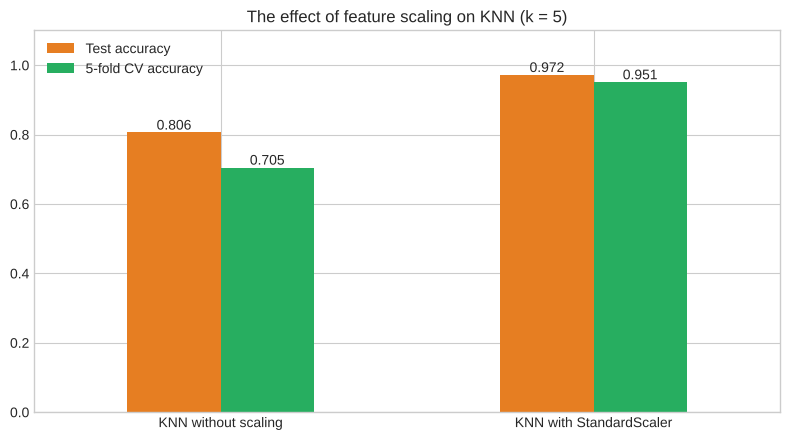

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# KNN (k=5) WITHOUT scaling
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
# KNN (k=5) WITH scaling, as a pipeline so the scaler is fitted on training data only
knn_scaled = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)

scale_results = pd.DataFrame({
    "Test accuracy": [knn_raw.score(X_test, y_test), knn_scaled.score(X_test, y_test)],
    "5-fold CV accuracy": [cross_val_score(KNeighborsClassifier(5), X_train, y_train, cv=cv).mean(),
                           cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), X_train, y_train, cv=cv).mean()],
}, index=["KNN without scaling", "KNN with StandardScaler"]).round(3)
display(scale_results)

ax = scale_results.plot(kind="bar", figsize=(8, 4.5), color=["#e67e22", "#27ae60"], rot=0)
ax.set_ylim(0, 1.1); ax.set_title("The effect of feature scaling on KNN (k = 5)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f")
plt.tight_layout()
plt.savefig("images/03_scaling_effect.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (scaling)
- Without scaling: test accuracy **0.806**, CV accuracy only **0.705**. The distance is almost entirely decided by `proline` and `magnesium`
- With `StandardScaler`: test accuracy **0.972**, CV accuracy **0.951**. A jump of **+17 points** from one preprocessing line
- Everything below uses a **Pipeline** (scaler + KNN), so the scaler is fitted only on each training fold (no data leakage)

## 🎚️ Step 3: Choosing K (Bias–Variance Trade-off)
- **Small K** (e.g. 1) → very flexible, follows the noise → **low bias, high variance** (overfitting)
- **Large K** → smoother, averages over many neighbors → **high bias, low variance** (underfitting)

We test K = 1 to 30 with 5-fold cross-validation **on the training set**.

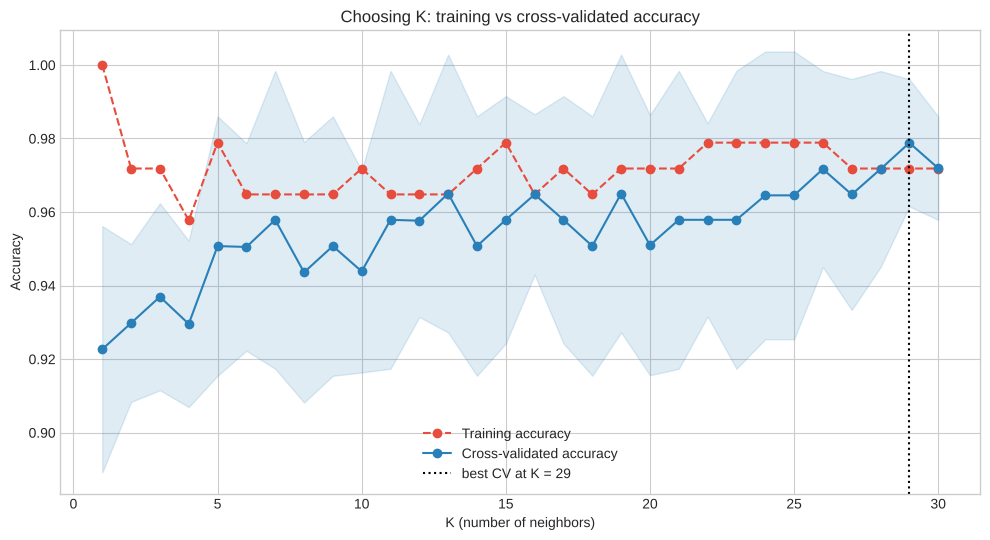

K = 1 : CV = 0.923 (train = 1.000)
K = 5 : CV = 0.951
Best  : K = 29, CV = 0.979


In [7]:
k_range = list(range(1, 31))
cv_mean, cv_std, train_acc = [], [], []
for k in k_range:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(pipe, X_train, y_train, cv=cv)
    cv_mean.append(scores.mean()); cv_std.append(scores.std())
    train_acc.append(pipe.fit(X_train, y_train).score(X_train, y_train))

cv_mean, cv_std = np.array(cv_mean), np.array(cv_std)
best_k = k_range[int(np.argmax(cv_mean))]

plt.figure(figsize=(10, 5.5))
plt.plot(k_range, train_acc, "o--", color="#e74c3c", label="Training accuracy")
plt.plot(k_range, cv_mean, "o-", color="#2980b9", label="Cross-validated accuracy")
plt.fill_between(k_range, cv_mean - cv_std, cv_mean + cv_std, color="#2980b9", alpha=0.15)
plt.axvline(best_k, color="black", linestyle=":", label=f"best CV at K = {best_k}")
plt.xlabel("K (number of neighbors)"); plt.ylabel("Accuracy")
plt.title("Choosing K: training vs cross-validated accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("images/04_choosing_k.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"K = 1 : CV = {cv_mean[0]:.3f} (train = {train_acc[0]:.3f})")
print(f"K = 5 : CV = {cv_mean[4]:.3f}")
print(f"Best  : K = {best_k}, CV = {cv_mean.max():.3f}")

### 📝 Observations (choosing K)
- **K = 1** memorises the training set (train accuracy **1.000**) but generalises worst (CV **0.923**): classic overfitting
- CV accuracy climbs to about **0.95 to 0.97 for K ≥ 5** and then flattens; the best value is **0.979 at K = 29**
- The curve is **flat** for K ≥ 5, so the differences between those K values (a single wine or two) are within noise. A moderate, odd K (5 to 15) is a safe choice, and **odd K avoids voting ties**

## 🔧 Step 4: Distance Metrics, Weighting & Grid Search

euclidean             0.951
manhattan             0.944
chebyshev             0.923
weights = uniform     0.951
weights = distance    0.951
dtype: float64


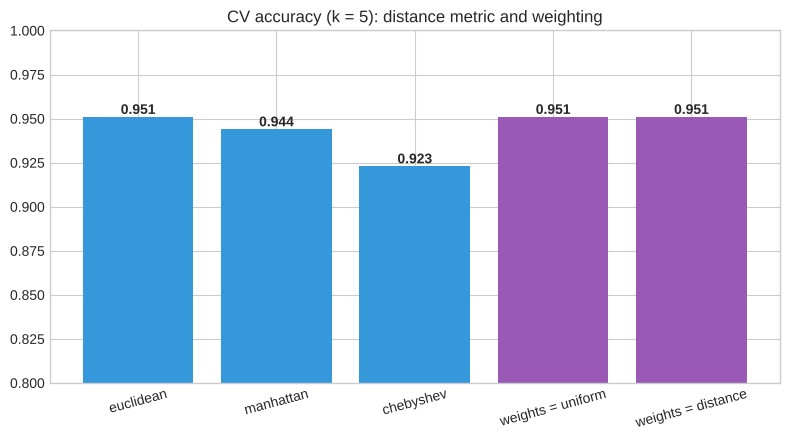

In [8]:
metric_scores = {}
for metric in ["euclidean", "manhattan", "chebyshev"]:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, metric=metric))
    metric_scores[metric] = cross_val_score(pipe, X_train, y_train, cv=cv).mean()
weight_scores = {}
for w in ["uniform", "distance"]:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, weights=w))
    weight_scores[f"weights = {w}"] = cross_val_score(pipe, X_train, y_train, cv=cv).mean()

all_scores = pd.Series({**metric_scores, **weight_scores}).round(3)
print(all_scores)

plt.figure(figsize=(8, 4.5))
bars = plt.bar(all_scores.index, all_scores.values, color=["#3498db"] * 3 + ["#9b59b6"] * 2)
for b, v in zip(bars, all_scores.values):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontweight="bold")
plt.ylim(0.8, 1.0); plt.xticks(rotation=15)
plt.title("CV accuracy (k = 5): distance metric and weighting")
plt.tight_layout()
plt.savefig("images/05_metrics_and_weights.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
param_grid = {
    "kneighborsclassifier__n_neighbors": list(range(1, 26)),
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__metric": ["euclidean", "manhattan", "chebyshev"],
}
grid = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()), param_grid, cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters :", {k.split("__")[1]: v for k, v in grid.best_params_.items()})
print(f"Best CV accuracy: {grid.best_score_:.3f}")
print("Combinations tried:", len(grid.cv_results_["params"]))

Best parameters : {'metric': 'manhattan', 'n_neighbors': 7, 'weights': 'uniform'}
Best CV accuracy: 0.979
Combinations tried: 150


### 📝 Observations (metrics & tuning)
- With K = 5: **Euclidean 0.951**, Manhattan 0.944, Chebyshev 0.923, and `uniform` vs `distance` weighting both **0.951**. On this clean dataset the choices matter little; Euclidean is a good default
- The grid search (150 combinations, all CV on the training set only) picks **K = 7, Manhattan, uniform weights** with CV accuracy **0.979**
- Treat this as "a good setting", not "the only setting": many nearby settings score almost the same

## 🎯 Step 5: Evaluate on the Held-Out Test Set
The test set is used **once**, for the final model chosen by cross-validation.

Test accuracy : 1.000  (36 of 36 correct)
Macro F1      : 1.000

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



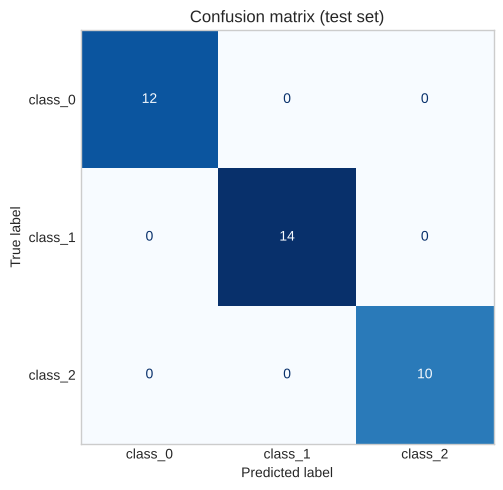

In [10]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(f"Test accuracy : {accuracy_score(y_test, y_pred):.3f}  ({int((y_pred == y_test).sum())} of {len(y_test)} correct)")
print(f"Macro F1      : {f1_score(y_test, y_pred, average='macro'):.3f}\n")
print(classification_report(y_test, y_pred, target_names=class_names))

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion matrix (test set)"); ax.grid(False)
plt.tight_layout()
plt.savefig("images/06_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (test performance)
- **Test accuracy 1.000** (36 of 36), macro F1 1.000, with a perfectly diagonal confusion matrix
- ⚠️ **Be honest about what this means:** the test set has only **36 wines**, so one mistake would be 97.2%. The default K = 5 model also scored **0.972**. The more reliable number is the **cross-validated accuracy of about 0.95 to 0.98**
- Wine is an easy, well-separated dataset: this project is about *understanding KNN*, not about chasing a record score

## 🗺️ Step 6: Decision Boundaries for Different K
To draw boundaries we need 2 features, so we use `alcohol` and `color_intensity` (a harder pair than the full 13 features).

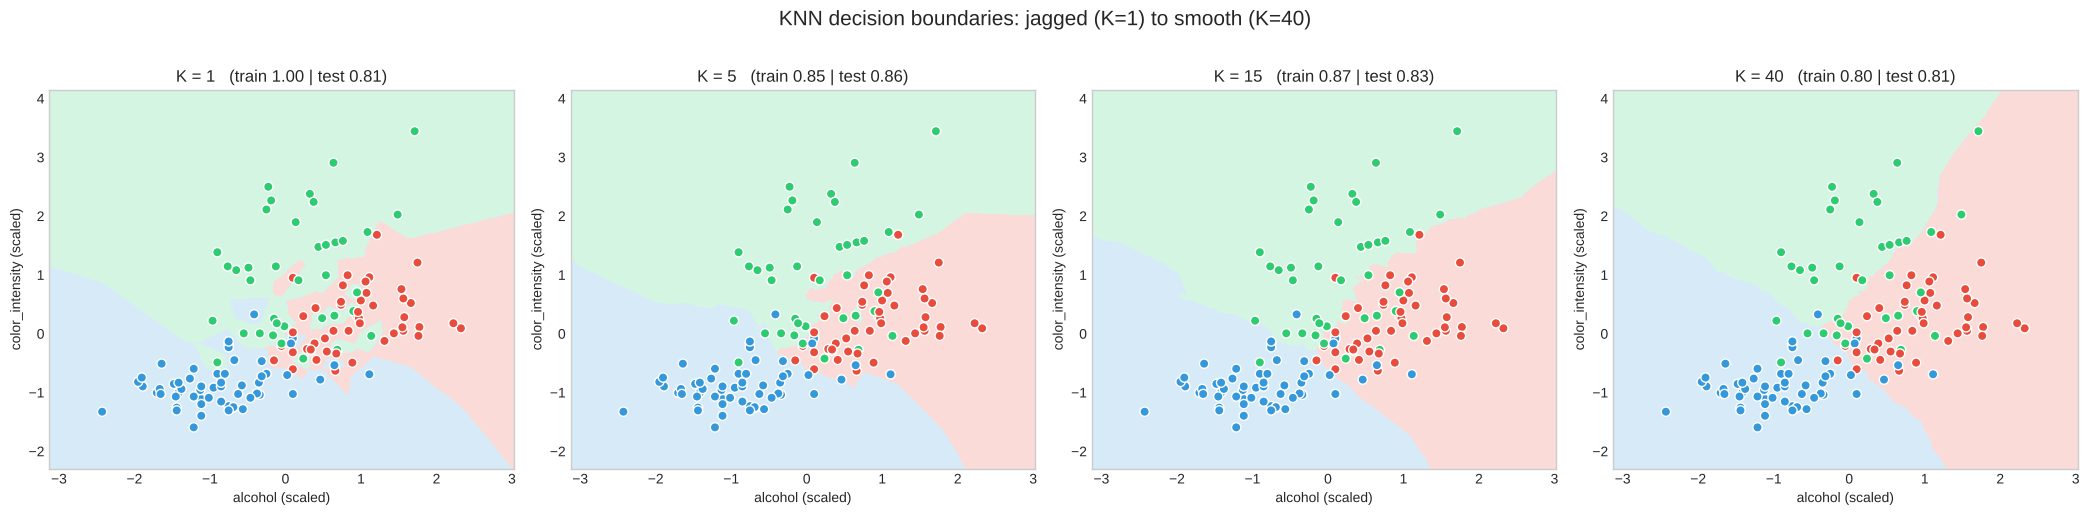

In [11]:
pair = ["alcohol", "color_intensity"]
Xp_train, Xp_test, yp_train, yp_test = train_test_split(X[pair], y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

scaler2 = StandardScaler().fit(Xp_train)
Ztr, Zte = scaler2.transform(Xp_train), scaler2.transform(Xp_test)

xx, yy = np.meshgrid(np.linspace(Ztr[:, 0].min() - 0.7, Ztr[:, 0].max() + 0.7, 300),
                     np.linspace(Ztr[:, 1].min() - 0.7, Ztr[:, 1].max() + 0.7, 300))
bg = ListedColormap(["#fadbd8", "#d6eaf8", "#d5f5e3"])
dots = ListedColormap(CLASS_COLORS)

fig, axes = plt.subplots(1, 4, figsize=(21, 5))
for ax, k in zip(axes, [1, 5, 15, 40]):
    m = KNeighborsClassifier(n_neighbors=k).fit(Ztr, yp_train)
    zz = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, cmap=bg)
    ax.scatter(Ztr[:, 0], Ztr[:, 1], c=yp_train, cmap=dots, edgecolor="white", s=45)
    ax.set_title(f"K = {k}   (train {m.score(Ztr, yp_train):.2f} | test {m.score(Zte, yp_test):.2f})")
    ax.set_xlabel("alcohol (scaled)"); ax.set_ylabel("color_intensity (scaled)"); ax.grid(False)
plt.suptitle("KNN decision boundaries: jagged (K=1) to smooth (K=40)", y=1.02, fontsize=15)
plt.tight_layout()
plt.savefig("images/07_decision_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (decision boundaries)
- **K = 1:** a jagged boundary with small "islands" around single points (overfitting, train accuracy 1.00)
- **K = 5 to 15:** a smooth boundary that follows the real class structure (best test accuracy at K = 5: 0.86 on this 2-feature view)
- **K = 40:** over-smoothed: the blue and red regions blur and the boundary cannot bend to the data (underfitting)
- This picture *is* the bias–variance trade-off

## 🌌 Step 7: The Curse of Dimensionality: KNN vs Logistic Regression
KNN treats **every feature equally** in the distance. We add pure-noise features (random numbers) and watch what happens,
comparing with logistic regression, which can learn to ignore useless features.

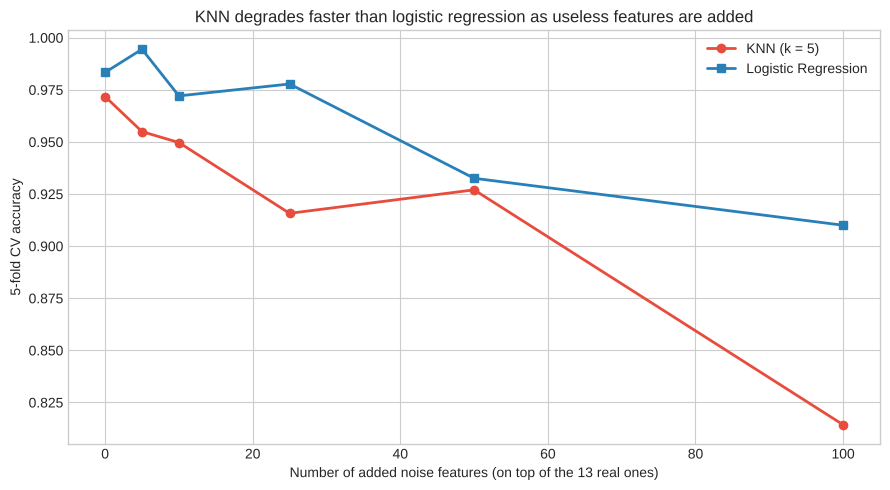

,KNN,Logistic Regression
Noise features,,
0,0.972,0.983
5,0.955,0.994
10,0.950,0.972
25,0.916,0.978
50,0.927,0.933
100,0.814,0.910


In [12]:
rng = np.random.RandomState(RANDOM_STATE)
noise_counts = [0, 5, 10, 25, 50, 100]
knn_cv, lr_cv = [], []
for n in noise_counts:
    Xn = np.hstack([X.values, rng.normal(size=(len(X), n))]) if n else X.values
    knn_cv.append(cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), Xn, y, cv=cv).mean())
    lr_cv.append(cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), Xn, y, cv=cv).mean())

plt.figure(figsize=(9, 5))
plt.plot(noise_counts, knn_cv, "o-", color="#e74c3c", linewidth=2, label="KNN (k = 5)")
plt.plot(noise_counts, lr_cv, "s-", color="#2980b9", linewidth=2, label="Logistic Regression")
plt.xlabel("Number of added noise features (on top of the 13 real ones)"); plt.ylabel("5-fold CV accuracy")
plt.title("KNN degrades faster than logistic regression as useless features are added")
plt.legend()
plt.tight_layout()
plt.savefig("images/08_curse_of_dimensionality.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"Noise features": noise_counts, "KNN": np.round(knn_cv, 3), "Logistic Regression": np.round(lr_cv, 3)}).set_index("Noise features")

### 📝 Observations (curse of dimensionality)
| Noise features added | KNN | Logistic Regression |
|---|---|---|
| 0 | 0.972 | 0.983 |
| 10 | 0.950 | 0.972 |
| 50 | 0.927 | 0.933 |
| 100 | **0.814** | **0.910** |

With 100 useless features, KNN loses **16 points** of accuracy; logistic regression loses 7. As dimensions grow, all points become almost equally far apart,
so "nearest" stops being meaningful. **Feature selection / dimensionality reduction (PCA)** matters a lot for KNN.

## 🔍 Step 8: Predict a New Wine & Inspect Its Neighbors

In [13]:
sample = X_test.iloc[[0]]
pred_class = best_model.predict(sample)[0]
proba = best_model.predict_proba(sample)[0]

scaler_f = best_model.named_steps["standardscaler"]
knn_f = best_model.named_steps["kneighborsclassifier"]
dist, idx = knn_f.kneighbors(scaler_f.transform(sample))

print(f"True class      : {class_names[y_test.iloc[0]]}")
print(f"Predicted class : {class_names[pred_class]}   (class probabilities: {np.round(proba, 2)})\n")
print(f"The {knn_f.n_neighbors} nearest training wines and their classes:")
neighbors = pd.DataFrame({"Neighbor": range(1, knn_f.n_neighbors + 1),
                          "Class": [class_names[c] for c in y_train.iloc[idx[0]]],
                          "Distance": dist[0].round(3)}).set_index("Neighbor")
neighbors

True class      : class_0
Predicted class : class_0   (class probabilities: [1. 0. 0.])

The 7 nearest training wines and their classes:


,Class,Distance
Neighbor,,
1,class_0,4.392
2,class_0,5.653
3,class_0,6.614
4,class_0,6.643
5,class_0,6.675
6,class_0,6.934
7,class_0,7.018


## ✅ Conclusion
- **Scaling is non-negotiable for KNN:** accuracy jumped from 0.705 to 0.951 (CV) with a single `StandardScaler`
- **K controls the bias–variance trade-off:** K = 1 overfits (train 1.00, CV 0.92), a moderate K (5 to 15) is a safe choice, and very large K over-smooths. CV accuracy ≈ **0.95 to 0.98**
- Distance metric and weighting matter little on this clean dataset; the grid search chose K = 7 with Manhattan distance (CV 0.979, test 1.000 on only 36 wines)
- KNN **suffers from irrelevant features**: 100 noise features cost 16 points, vs 7 for logistic regression
- KNN is simple, needs no training, and works well on small, low-dimensional, well-scaled data, but prediction is slow on big data and it is sensitive to scale and noise

## 🎤 Interview Questions: Short Answers
1. **How does KNN work?** To predict a point, find its K closest training points (by a distance metric) and take a majority vote (classification) or the average (regression). There is no real "training": it stores the data (a **lazy learner**).
2. **How do you choose K?** With cross-validation: try a range of K and pick the best CV score (watch the bias-variance trade-off). Prefer odd K for binary problems to avoid ties, and a simpler (larger) K when scores are tied.
3. **Why is feature scaling important?** KNN uses distances, so features with large numeric ranges dominate. Here scaling raised CV accuracy from 0.705 to 0.951. Fit the scaler on training data only (use a Pipeline).
4. **Which distance metrics can be used?** Euclidean (default), Manhattan (better with many dimensions or outliers), Minkowski (general form), Chebyshev, cosine (text / sparse data), Hamming (categorical).
5. **What is the curse of dimensionality?** In high dimensions the distances between points become nearly equal, so "nearest" loses meaning and irrelevant features swamp the signal. Fix with feature selection or PCA, and more data.
6. **What is the bias-variance trade-off in KNN?** Small K = low bias, high variance (jagged boundary, overfits). Large K = high bias, low variance (over-smooth, underfits).
7. **Pros and cons of KNN?** Pros: simple, no training, naturally multiclass, non-linear boundaries. Cons: slow prediction and high memory on large data, sensitive to scale, noise, irrelevant features and imbalanced classes.
8. **Time complexity?** Training is O(1) (just store the data); prediction is O(n · d) per query by brute force. KD-trees / ball trees or approximate nearest neighbors speed it up in low dimensions.
9. **Can KNN do regression?** Yes: predict the (optionally distance-weighted) average of the K neighbors' target values (`KNeighborsRegressor`).
10. **How do you handle class imbalance in KNN?** Use distance weighting, resampling (SMOTE / undersampling), stratified splits and metrics such as F1 or recall, because the majority class dominates the vote.
11. **What does `weights='distance'` do?** Closer neighbors get larger votes (weight = 1 / distance), which helps when classes overlap or K is large.